# DBAC with ideal DME: the recursion depth $k$ sweep

This notebook studies double-bracket algorithmic cooling (DBAC) in the idealized limit
where density matrix exponentiation (DME) is replaced by the *exact* unitary it
approximates ($M\to\infty$, no Trotter error -- see
[`dme_channel.ipynb`](dme_channel.ipynb) for how real finite-$M$ DME compares to this
limit). In this limit, DB-QITE is a purely analytical recursion:

1. Use the current state $\rho_k$ as both data and instruction to build the "group
   commutator" unitary that implements one step of steepest-descent imaginary-time
   evolution.
2. Numerically optimize the step size $s_k$ to minimize the data-qubit energy after the
   step.
3. Repeat for $k = 1, \dots, 6$ recursion steps.

Reproduced here is the paper's "rainbow" figure, which sweeps the fidelity of the initial
state with the ground state and shows how the achievable final fidelity improves as more
recursion steps $k$ are used -- directly illustrating the Nernst-principle-like trade-off
between cooling performance and the number of quantum instructions consumed.

All of the optimization and sweep logic lives in
[`scripts/dbac_ideal_dme.py`](../scripts/dbac_ideal_dme.py); the three-panel figure is
built by `visualization.dbac_plots.plot_ideal_dme_summary`.

In [3]:
%matplotlib inline
import sys
sys.path.append('..')

from matplotlib import cm
import numpy as np

from visualization import use_paper_style, figure_size
from scripts.dbac_ideal_dme import (
    optimize_ideal_dme_steps, load_or_fit_optimal_s_Mk, run_ideal_dme_sweep,
)

use_paper_style(font_size=10, figsize=figure_size("PRD", "twocol", aspect=2))

RAINBOW_COLORS = [(r * 0.8, g * 0.8, b * 0.8, a) for r, g, b, a in cm.rainbow(np.linspace(1, 0, 6))]
MARKERS = ['o', 's', '^', '*', 'P', '*', 'h']

[Qibo 0.3.5|INFO|2026-10-12 12:55:01]: Using numpy backend on /CPU:0


## Step 1: optimize the recursion step sizes

`optimize_ideal_dme_steps` greedily finds $s_1, \dots, s_7$ for a fixed initial state
$\psi_0 = (|0\rangle + i|1\rangle)/\sqrt 2$, minimizing the energy after each additional
step. `load_or_fit_optimal_s_Mk` does the same, but for every (Trotter steps $M$,
recursion depth $k$) pair, used by the Trotterized-DME notebooks; the result is cached to
`optimal_s_Mk.npy` so it only needs to be fit once.

In [4]:
optimal_s = optimize_ideal_dme_steps(max_k=7)
optimal_s_Mk = load_or_fit_optimal_s_Mk(max_k=7, max_M=10)
optimal_s_kM = optimal_s_Mk.T
np.round(optimal_s, 3)

array([0.955, 0.737, 0.701, 0.696, 0.696, 0.7  , 0.7  ])

## Step 2: sweep the initial state over $R_X(\theta)|1\rangle$

For each recursion depth $k=1,\dots,6$, run DB-QITE with the ideal DME unitary on every
initial state in the sweep, and convert the final energy to a fidelity with the ground
state via $F = (1-E)/2$.

In [5]:
fidelities_initial, initial_curve, dict_fid = run_ideal_dme_sweep(optimal_s, max_k=6)

0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of interval reached
0 0 0.01 --- Warning edge of inter

## Step 3: the summary figure

/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)
/home/kay-otic/Code/dbac/jupyter_notebooks/../visualization/dbac_plots.py:402: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/text.py:1698: ComplexWarning: Casting complex values to real discards the imaginary part
  y = float(self.convert_yunits(y))
/home/kay-otic/Code/dbac/.venv/lib/python3.13/site-packages/matplotlib/text.py:1013: ComplexWarning: Casting complex values to real discards the imaginary part
  y = float(self.convert_yunits(self._y))
/home/

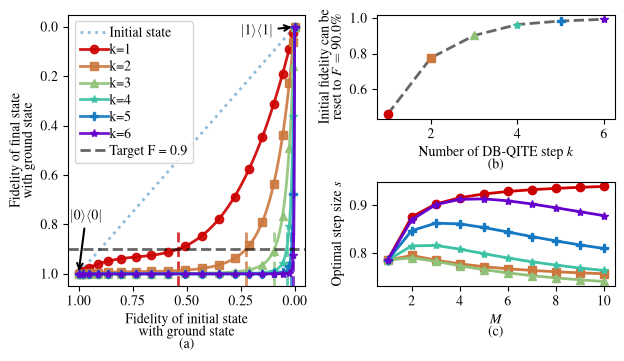

In [6]:
from visualization import plot_ideal_dme_summary

plot_ideal_dme_summary(
    fidelities_initial, initial_curve, dict_fid, optimal_s_kM,
    target_fidelity=0.9, colors=RAINBOW_COLORS, markers=MARKERS,
);

Panel (a) is the fidelity-fidelity plot across $k$, with a dashed vertical line at
the worst initial-state fidelity that each $k$ can still reset to the $F=90\%$ target.
Panel (b) shows that this "reach" improves monotonically with $k$. Panel (c) shows how
the optimal step size $s$ depends on the number of Trotter steps $M$ used to implement
the (non-ideal) DME channel, for each $k$.

---
To regenerate this figure from the command line instead of this notebook, run:

```bash
python scripts/dbac_ideal_dme.py
```